In [4]:
# Cell 1: Package Installation
!pip install qiskit qiskit-aer scikit-learn matplotlib numpy

  Using cached qiskit-2.6.1-cp310-abi3-manylinux_2_28_x86_64.whl.metadata (14 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.6/9.6 MB 42.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.2/14.2 MB 96.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 74.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [qiskit-aer]


In [5]:
# Cell 2: Imports
import numpy as np
import matplotlib.pyplot as plt

# Classical ML & Evaluation
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix

# Quantum Computing primitives
import qiskit
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector

print(f"Qiskit version: {qiskit.__version__}")
print(f"NumPy version: {np.__version__}")


Qiskit version: 2.6.1
NumPy version: 2.1.3


In [9]:
X[:6]

array([[-1.06103127,  0.373484  ],
       [ 0.15464993,  1.13969202],
       [ 0.1183678 , -0.20124259],
       [ 1.2622548 , -0.3308151 ],
       [ 0.92812386, -0.02784885],
       [-0.4476828 ,  0.78006198]])

In [11]:
y[:6]

array([0, 0, 1, 1, 0, 0])

In [6]:
# Cell 3: Data preparation
X, y = make_moons(n_samples=90, noise=0.15, random_state=42)

# 60 samples for training, 30 samples for testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.33, random_state=42
)

print(f"Training samples: {len(X_train)}")
print(f"Testing samples:  {len(X_test)}")
print(f"Feature count:    {X.shape[1]}")

Training samples: 60
Testing samples:  30
Feature count:    2


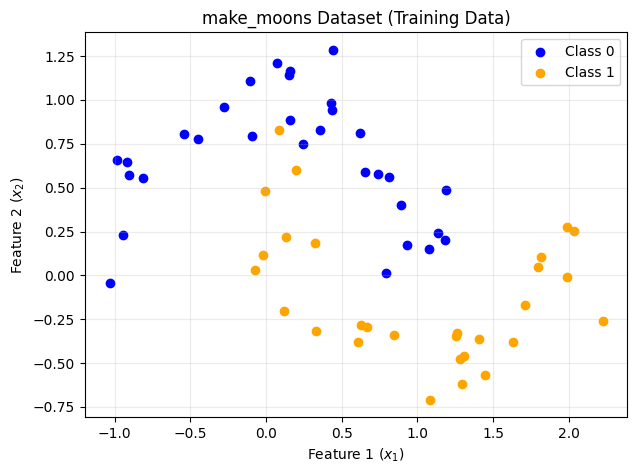

In [12]:
# Cell 4: Data visualization
plt.figure(figsize=(7, 5))
plt.scatter(X_train[y_train == 0, 0], X_train[y_train == 0, 1], color='blue', label='Class 0')
plt.scatter(X_train[y_train == 1, 0], X_train[y_train == 1, 1], color='orange', label='Class 1')
plt.title("make_moons Dataset (Training Data)")
plt.xlabel("Feature 1 ($x_1$)")
plt.ylabel("Feature 2 ($x_2$)")
plt.grid(True, alpha=0.25)
plt.legend()
plt.show()

In [14]:
# Cell 5: Classical SVM Baselines
for kernel in ['linear', 'poly', 'rbf']:
    clf = SVC(kernel=kernel)
    clf.fit(X_train, y_train)
    acc = accuracy_score(y_test, clf.predict(X_test))
    print(f"Classical SVM ({kernel:6s} kernel) Accuracy: {acc:.3f}")

Classical SVM (linear kernel) Accuracy: 0.867
Classical SVM (poly   kernel) Accuracy: 0.900
Classical SVM (rbf    kernel) Accuracy: 0.967


In [15]:
# Cell 6: Quantum Feature Map Circuit
def quantum_feature_map(x):
    """
    Encodes 2D classical feature vector into a 2-qubit quantum state.
    """
    qc = QuantumCircuit(2)
    x1, x2 = x[0], x[1]

    # Superposition
    qc.h(0)
    qc.h(1)

    # Feature rotation
    qc.rz(x1, 0)
    qc.rz(x2, 1)

    # Entanglement & non-linear cross-term
    qc.cx(0, 1)
    qc.rz(x1 * x2, 1)
    qc.cx(0, 1)

    return qc

# Inspect circuit for the first training point
demo_qc = quantum_feature_map(X_train[0])
print(demo_qc.draw())

     ┌───┐┌──────────────┐                         
q_0: ┤ H ├┤ Rz(-0.94579) ├──■───────────────────■──
     ├───┤├─────────────┬┘┌─┴─┐┌─────────────┐┌─┴─┐
q_1: ┤ H ├┤ Rz(0.23071) ├─┤ X ├┤ Rz(-0.2182) ├┤ X ├
     └───┘└─────────────┘ └───┘└─────────────┘└───┘


In [16]:
# Cell 7: Quantum State Overlap Computation
def compute_quantum_kernel_entry(x, z):
    qc_x = quantum_feature_map(x)
    qc_z = quantum_feature_map(z)

    # Compose U(x) followed by U^\dagger(z)
    overlap_circuit = QuantumCircuit(2)
    overlap_circuit.compose(qc_x, inplace=True)
    overlap_circuit.compose(qc_z.inverse(), inplace=True)

    # Simulate statevector
    state = Statevector.from_instruction(overlap_circuit)
    probabilities = state.probabilities()

    # Probability of measuring |00> (index 0)
    return float(probabilities[0])

# Verify on identical and distinct points
print(f"Self-similarity K(x0, x0): {compute_quantum_kernel_entry(X_train[0], X_train[0]):.4f}")
print(f"Cross-similarity K(x0, x1): {compute_quantum_kernel_entry(X_train[0], X_train[1]):.4f}")

Self-similarity K(x0, x0): 1.0000
Cross-similarity K(x0, x1): 0.0717


In [17]:
# Cell 8: Gram Matrix Generator
def build_kernel_matrix(A, B=None):
    if B is None:
        B = A
    n_a = len(A)
    n_b = len(B)
    matrix = np.zeros((n_a, n_b))

    is_symmetric = (B is A)
    for i in range(n_a):
        start_j = i if is_symmetric else 0
        for j in range(start_j, n_b):
            val = compute_quantum_kernel_entry(A[i], B[j])
            matrix[i, j] = val
            if is_symmetric:
                matrix[j, i] = val  # Kernel matrix is symmetric: K(x, z) = K(z, x)
    return matrix

# Compute Training and Testing Kernel Matrices
K_train = build_kernel_matrix(X_train)
K_test = build_kernel_matrix(X_test, X_train)

print(f"K_train shape: {K_train.shape}")
print(f"K_test shape:  {K_test.shape}")

K_train shape: (60, 60)
K_test shape:  (30, 60)


Is diagonal all 1s?: True
Is matrix symmetric?: True


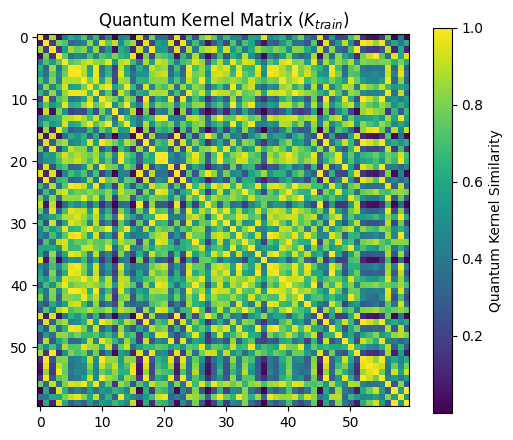

In [18]:
# Cell 9: Verify Kernel Properties & Plot
print("Is diagonal all 1s?:", np.allclose(np.diag(K_train), 1.0))
print("Is matrix symmetric?:", np.allclose(K_train, K_train.T))

plt.figure(figsize=(6, 5))
plt.imshow(K_train, cmap='viridis', origin='upper')
plt.colorbar(label='Quantum Kernel Similarity')
plt.title("Quantum Kernel Matrix ($K_{train}$)")
plt.show()

In [19]:
# Cell 10: QSVM Training and Evaluation
qsvm = SVC(kernel="precomputed", C=1.0)
qsvm.fit(K_train, y_train)

# Predict on test set using K_test
y_pred = qsvm.predict(K_test)

# Metrics
acc = accuracy_score(y_test, y_pred)
cm = confusion_matrix(y_test, y_pred)

print(f"Quantum Kernel SVM Accuracy: {acc:.4f}\n")
print("Confusion Matrix:")
print(cm)

Quantum Kernel SVM Accuracy: 0.8000

Confusion Matrix:
[[13  1]
 [ 5 11]]
